# Econ 5200 PS3 — The Rollout That Looked Like It Worked

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 9-11 · 100 points · your role: Senior consultant, policy evaluation

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is senior consultant's audience, not a grader with a kernel.



## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: The Canonical Case, Already In Your Hands (15 pts)

### Step 1.1: Carry the replication over

In [2]:
import io
import re
import urllib.request
import zipfile

raw = urllib.request.urlopen(
    "https://davidcard.berkeley.edu/data_sets/njmin.zip", timeout=60).read()
z = zipfile.ZipFile(io.BytesIO(raw))

# public.dat is fixed-width numbers; the codebook supplies a name for each column
names = re.findall(r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d",
                   z.read("codebook").decode("latin-1"), re.M)
ck = pd.read_csv(io.BytesIO(z.read("public.dat")), sep=r"\s+", header=None,
                 names=names, na_values=["."])

# Full-time-equivalent employment, Card & Krueger's outcome: full-timers, managers and
# half of part-timers, in each wave (a 2 at the end of a name marks the second wave)
ck["fte_before"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]
ck["fte_after"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]

print(f"{len(ck)} restaurants: {int((ck.STATE == 1).sum())} NJ, "
      f"{int((ck.STATE == 0).sum())} PA")

means_by_state = ck.groupby("STATE")[["fte_before", "fte_after"]].mean()
nj, pa = means_by_state.loc[1], means_by_state.loc[0]    # STATE is 1 for New Jersey, 0 for Pennsylvania

did = (nj.fte_after - nj.fte_before) - (pa.fte_after - pa.fte_before)

print(f"\n{'':<12}{'before':>9}{'after':>9}{'change':>9}")
print("-" * 39)
print(f"{'NJ (treated)':<12}{nj.fte_before:>9.2f}{nj.fte_after:>9.2f}"
      f"{nj.fte_after - nj.fte_before:>9.2f}")
print(f"{'PA (control)':<12}{pa.fte_before:>9.2f}{pa.fte_after:>9.2f}"
      f"{pa.fte_after - pa.fte_before:>9.2f}")
print("-" * 39)
print(f"{'DiD':<12}{'':>18}{did:>9.2f}")

assert round(did, 2) == 2.75
print(f"\nDiD value passes the checkpoint")

410 restaurants: 331 NJ, 79 PA

               before    after   change
---------------------------------------
NJ (treated)    20.44    21.03     0.59
PA (control)    23.33    21.17    -2.17
---------------------------------------
DiD                                2.75

DiD value passes the checkpoint


> **Checkpoint:** the two-by-two is **+2.75 FTE** to two decimal places. If it is not, your FTE construction or your wave assignment is wrong; fix it before anything else.


### Step 1.2: The same number from a regression

In [3]:
data_wide = ck[["SHEET", "STATE", "CHAIN", "fte_before", "fte_after"]].copy()
data_wide.insert(0, "store_id", range(len(data_wide)))

data_long = data_wide.melt(id_vars=["store_id", "SHEET", "STATE"],
                           value_vars=["fte_before", "fte_after"],
                           var_name="wave", value_name="fte")
data_long["post"] = (data_long["wave"] == "fte_after").astype(int)
data_long = data_long.sort_values(["store_id", "post"]).reset_index(drop=True)

dl = data_long.dropna(subset=["fte"])

did_fit = smf.ols("fte ~ STATE * post", data=dl).fit(
    cov_type="cluster", cov_kwds={"groups": dl["store_id"]})

print(did_fit.params)

Intercept     23.331
STATE         -2.892
post          -2.166
STATE:post     2.754
dtype: float64


The regression here gives the same answer when run through the statistics module as when it was calculated by hand (excluding some differences created by rounding values). The STATE row is -2.89, which represents the value before the policy, showing that NJ had about 2.9 less FTE than the PA restaurants, and post carries the value of -2.17 for the PA no-policy restaurants, which shows that those restaurants lost around 2.2 FTE between the two periods. Neither actually measures the effect of the minimum wage because the STATE value is the difference between the two states prior to anything and demonstrates the differences between the two cohorts. Post is the variable measuring the change with no policy whatsoever, so it reflects the changes that hit everyone (both cohorts).

## Phase 2: Why Their Design Fails (35 pts)

### Step 2.1: Build their panel, and reproduce their number (20 pts)

In [4]:
rng_jobs = np.random.default_rng(42)

base_effect = 3.0
growth = 0.5
county_sd = 2.0
year_sd = 1.0
board_shock_sd = 1.5
noise_sd = 1.0
baseline_outcome = 10

n_boards, counties_per_board, n_years = 8, 5, 12
n_counties = n_boards * counties_per_board
years = np.arange(1, n_years + 1)

adoption_year = {0: 3, 1: 3, 2: 3, 3: 4, 4: 5, 5: 6, 6: 6, 7: np.inf}

county_effect = rng_jobs.normal(0, county_sd, n_counties)
year_effect = rng_jobs.normal(0, year_sd, n_years)
board_year_shock = rng_jobs.normal(0, board_shock_sd, (n_boards, n_years))

rows = []
for county in range(n_counties):
    board = county // counties_per_board
    first_year = adoption_year[board]
    for year in years:
        treated = int(year >= first_year)
        true_effect = (base_effect + growth * (year - first_year) ** 2) if treated else 0.0
        outcome = (baseline_outcome + county_effect[county] + year_effect[year - 1]
                   + board_year_shock[board, year - 1]
                   + true_effect + rng_jobs.normal(0, noise_sd))
        rows.append({"county": county, "board": board, "year": year,
                     "adoption_year": first_year, "treated": treated,
                     "true_effect": true_effect, "outcome": outcome})

panel = pd.DataFrame(rows)

true_att = panel.loc[panel["treated"] == 1, "true_effect"].mean()

twfe = smf.ols("outcome ~ treated + C(county) + C(year)", data=panel).fit(
    cov_type="cluster", cov_kwds={"groups": panel["board"]})
twfe_estimate = twfe.params["treated"]

print(f"Base effect:          {base_effect}")
print(f"Growth (× exposure²): {growth}")
print(f"County SD:            {county_sd}")
print(f"Year SD:              {year_sd}")
print(f"Board-shock SD:       {board_shock_sd}")
print(f"Noise SD:             {noise_sd}")
print(f"Panel: {len(panel)} county-years, {panel['treated'].sum()} treated")
print(f"True ATT:      {true_att:.3f}")
print(f"TWFE estimate: {twfe_estimate:.3f}")
print(f"Bias:          {twfe_estimate - true_att:.3f}")

Base effect:          3.0
Growth (× exposure²): 0.5
County SD:            2.0
Year SD:              1.0
Board-shock SD:       1.5
Noise SD:             1.0
Panel: 480 county-years, 305 treated
True ATT:      14.320
TWFE estimate: 2.429
Bias:          -11.891


The setup here matches the situation we are presented with and runs on its own rng seed so that the panel stays fixed. All variables used throughout the code are defined in lines 1–19 and serve as the foundation for building this scenario. The adoption year is a dictionary of the boards and the year each one adopts the policy, and boards adopting in the same year form a cohort. Next we set up the random draws, where county_effect is a random number determined by some characteristics of the county that affect its labor market. The year effect is the effect of the period, such as a good harvest or something along those lines, that is tied to the period and affects all counties together. Lastly, the board effect is the effect of the board, and it affects all of the counties that sit under the jurisdiction of that board (it represents the board's decisions that impact its counties).

After this we build the rows using a for loop. The outer loop goes through the counties, and for each county it finds the county's board and then looks up the board's first adoption year. This sits in the outer loop because it doesn't change across years for a given county. After this we move to the inner loop, which runs 12 times for each county (once for every year). We tag a county-year as treated once the county has reached its board's first adoption year, and the true effect is calculated only for those treated county-years. This effect is measured from the adoption year and grows with the square of the years of exposure, so it speeds up the longer a county is treated. The rest is the actual outcome, which is built from the variables defined at the top of the code cell.

Under staggered adoption TWFE misses the mark by a substantial amount. TWFE gives 2.43, while the true average treatment effect on the treated is 14.32, a bias of −11.89. This shows that under staggered adoption this approach creates issues because already-treated counties are being used as controls even though their outcomes are still rising.

### Step 2.2: Decompose it (15 pts)

In [5]:
cohorts = sorted(set(adoption_year.values()))
share = panel.drop_duplicates("county")["adoption_year"].value_counts(normalize=True)

def did(treat, control, pre, post, col):
    mean = lambda g, yrs: panel.loc[(panel["adoption_year"] == g)
                                    & panel["year"].isin(yrs), col].mean()
    return (mean(treat, post) - mean(treat, pre)) - (mean(control, post) - mean(control, pre))

rows = []
for i, k in enumerate(cohorts):
    for l in cohorts[i + 1:]:
        n_k, n_l = share[k], share[l]
        d_k = max(0, (n_years - k + 1) / n_years)
        d_l = max(0, (n_years - l + 1) / n_years)
        n_kl = n_k / (n_k + n_l)
        pre, mid, post = years[years < k], years[(years >= k) & (years < l)], years[years >= l]

        rows.append({"type": "treated vs never" if np.isinf(l) else "early vs not-yet-treated",
                     "treated": k, "control": l,
                     "weight": ((n_k + n_l) * (1 - d_l)) ** 2 * n_kl * (1 - n_kl)
                               * (d_k - d_l) / (1 - d_l) * (1 - d_k) / (1 - d_l),
                     "estimate": did(k, l, pre, mid, "outcome"),
                     "noise_free": did(k, l, pre, mid, "true_effect")})
        if np.isfinite(l):
            rows.append({"type": "late vs already-treated", "treated": l, "control": k,
                         "weight": ((n_k + n_l) * d_k) ** 2 * n_kl * (1 - n_kl)
                                   * (d_l / d_k) * (d_k - d_l) / d_k,
                         "estimate": did(l, k, mid, post, "outcome"),
                         "noise_free": did(l, k, mid, post, "true_effect")})

bacon = pd.DataFrame(rows)
bacon["weight"] /= bacon["weight"].sum()

true_on_treated = panel.loc[panel["treated"] == 1, "true_effect"]

print(bacon.round(3))
print(f"\nWeighted sum of 2x2s: {(bacon['weight'] * bacon['estimate']).sum():.3f} "
      f"(TWFE: {twfe_estimate:.3f})")
print(bacon.groupby("type")["weight"].sum().round(3))
print(f"\nTrue effects range: [{true_on_treated.min():.3f}, {true_on_treated.max():.3f}]")

                        type  treated  control  weight  estimate  noise_free
0   early vs not-yet-treated        3      4.0   0.012     1.738       3.000
1    late vs already-treated        4      3.0   0.052    -4.079      -1.500
2   early vs not-yet-treated        3      5.0   0.023     2.920       3.250
3    late vs already-treated        5      3.0   0.093    -7.152      -5.750
4   early vs not-yet-treated        3      6.0   0.070     3.695       3.833
5    late vs already-treated        6      3.0   0.244    -9.321      -9.667
6           treated vs never        3      inf   0.116    18.012      17.250
7   early vs not-yet-treated        4      5.0   0.006     0.515       3.000
8    late vs already-treated        5      4.0   0.015    -2.163      -1.000
9   early vs not-yet-treated        4      6.0   0.023     2.860       3.250
10   late vs already-treated        6      4.0   0.054    -2.992      -4.750
11          treated vs never        4      inf   0.052    14.137      14.333

The decomposition in this case is exact, since the weighted sum of the 2x2s is 2.429, and that fully matches the TWFE figure, which makes TWFE nothing more than their weighted average. If we look at the rows that we calculated estimates for, we can see that there are certain comparisons that should not be made (they are forbidden). These are the "late vs. already-treated" rows, where later-adopting boards are compared against boards that adopted earlier, and these carry almost 50% of the weight (48.5%). A concrete example of this is board cohort 6 vs 3, which has an estimate and noise_free value of -9.321 and -9.667. The values are negative because these boards are used as controls despite already being treated, and their effect keeps growing and growing. They have rising outcomes because of the policy, so taking away this change in the comparison takes the true effect out of the estimate. Since noise_free shows a very similar number, the negative effect is not just noise but rather comes from the design of what we are doing. Every weight here is positive, but the forbidden 2x2s are not averages of true effects, so TWFE doesn't have to sit between the smallest and largest true effects. Our true effects run from 3.0 to 43.5 and TWFE is 2.429, which is below all of them.

## Phase 3: The Estimate That Survives (40 pts)

### Step 3.1: Rebuild it correctly (15 pts)

In [6]:
from src.did_utils import att_by_cohort_period, overall_att

cells = att_by_cohort_period(panel, time="year", outcome="outcome", cohort="adoption_year")
cells_true = att_by_cohort_period(panel, time="year", outcome="true_effect", cohort="adoption_year")

clean_att = overall_att(cells)
clean_att_true = overall_att(cells_true)

print(f"Clean ATT:             {clean_att:.3f}")
print(f"Clean ATT, noise-free: {clean_att_true:.3f}")
print(f"True ATT:              {true_att:.3f}")
print(f"TWFE:                  {twfe_estimate:.3f}")

Clean ATT:             15.545
Clean ATT, noise-free: 14.320
True ATT:              14.320
TWFE:                  2.429


The function for each cohort is imported and works properly, and it comes from a previous lab. It only uses the never-treated cohort or those who are not yet treated as controls, the latter only up until they begin treatment. Afterwards the cells are averaged. The noise-free ATT is 14.32, which is identical to the ATT that was designed into our sample study. Against the previously calculated TWFE we can see that TWFE has very clearly underestimated the true effect. The noise-free estimate is there to show that our clean ATT isn't actually off from the true design of the experiment, and the clean ATT has already removed the forbidden comparisons, which is why it is so much closer to the truth.

### Step 3.2: The assumption you cannot test (12 pts)

            -5    -4    -3    -2   -1    0     1     2     3      4      5      6      7      8      9 
estimate -1.58 -2.17 -0.46 -1.29  0.0  2.38  3.91  5.44  8.35  12.24  15.83  22.03  29.68  35.99  45.64
truth     0.00  0.00  0.00  0.00  0.0  3.00  3.50  5.00  7.50  11.00  15.50  21.00  27.50  35.00  43.50


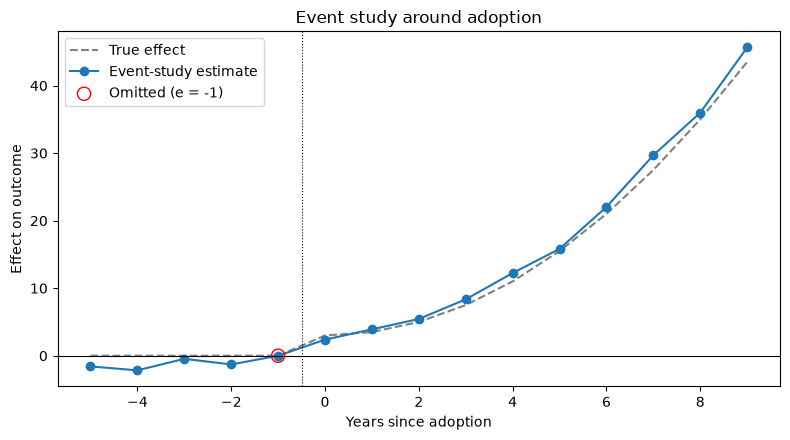

In [7]:
ref_period = -1
es_data = panel.copy()
es_data["event_time"] = np.where(np.isfinite(es_data["adoption_year"]),
                                 es_data["year"] - es_data["adoption_year"], np.nan)
event_times = sorted(int(e) for e in es_data["event_time"].dropna().unique())

dummy_name = {}
event_time_column = {}
for e in event_times:
    if e == ref_period:
        continue
    event_time_column[e] = f"pre{-e}" if e < 0 else f"post{e}"
    es_data[event_time_column[e]] = (es_data["event_time"] == e).astype(int)

es_fit = smf.ols("outcome ~ " + " + ".join(event_time_column.values())
                 + " + C(county) + C(year)", data=es_data).fit()
es_estimates = pd.Series({e: 0.0 if e == ref_period else es_fit.params[event_time_column[e]]
                          for e in event_times})
es_truth = pd.Series({e: base_effect + growth * e ** 2 if e >= 0 else 0.0
                      for e in event_times})
print(pd.DataFrame({"estimate": es_estimates, "truth": es_truth}).round(2).T.to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(es_truth.index, es_truth.values, "--", color="grey", label="True effect")
ax.plot(es_estimates.index, es_estimates.values, "o-", label="Event-study estimate")
ax.scatter([ref_period], [0], s=90, facecolors="none", edgecolors="red",
           label=f"Omitted (e = {ref_period})", zorder=3)

ax.axhline(0, color="black", lw=0.8)
ax.axvline(-0.5, color="black", ls=":", lw=0.8)
ax.set_xlabel("Years since adoption")
ax.set_ylabel("Effect on outcome")
ax.set_title("Event study around adoption")
ax.legend()
plt.tight_layout()
plt.show()

Before the treatment takes place we can see that the true effect lies flat at 0 until the treatment period begins. There is some noise in the study itself that pushes the estimates below 0 before the treatment begins. The coefficients before treatment are: `-1.58 -2.17 -0.46 -1.29  0.0`. The assumption built in is that both of the groups would be moving in parallel and the coefficients would stay around 0 if there was no treatment taking place. The assumption in this case does hold though, since the implementation wasn't taking place due to some grander economic changes, as each county implemented the treatment at different points in time. Also, in these counties nothing else has changed, and the effects that happen each year are random and affect each county in the same manner. As such, the pre-trends are consistent with the design itself, but they are not evidence of the actual design.

### Step 3.3: Inference with what you have (10 pts, plus 3 for the module)

In [8]:
twfe_formula = "outcome ~ treated + C(county) + C(year)"
se_options = {
    "Default": {},
    "County-clustered": {"cov_type": "cluster", "cov_kwds": {"groups": panel["county"]}, "use_t": True},
    "Board-clustered": {"cov_type": "cluster", "cov_kwds": {"groups": panel["board"]}, "use_t": True},
}

se_rows = []
for label, options in se_options.items():
    fit = smf.ols(twfe_formula, data=panel).fit(**options)
    se_rows.append({"SE type": label, "estimate": round(fit.params["treated"], 3),
                    "se": round(fit.bse["treated"], 3), "t": round(fit.tvalues["treated"], 2),
                    "p": round(fit.pvalues["treated"], 4)})

print(pd.DataFrame(se_rows).to_string(index=False))

         SE type  estimate    se    t     p
         Default     2.429 1.012 2.40 0.017
County-clustered     2.429 2.347 1.03 0.307
 Board-clustered     2.429 5.519 0.44 0.673


The module the brief asks for: start from Lab 11's `src/did_utils.py` (`two_by_two`, `event_study`) and the notebook's `clean_att`, then add the clustered-inference wrapper and, in Phase 4, the bootstrap. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [9]:
%%writefile src/did_toolkit.py
"""Difference-in-differences toolkit (ECON 5200 PS3), extending Lab 11's did_utils.py."""
from __future__ import annotations

from collections.abc import Sequence

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

WEBB_WEIGHTS = np.array([-np.sqrt(1.5), -1.0, -np.sqrt(0.5), np.sqrt(0.5), 1.0, np.sqrt(1.5)])


def _never_treated(df: pd.DataFrame, time: str, cohort: str) -> pd.Series:
    """Flag never-treated units (cohort is inf or after the last period)."""
    adoption = df[cohort].astype(float)
    return ~np.isfinite(adoption) | (adoption > df[time].max())


def two_by_two(df: pd.DataFrame, outcome: str, time: str, cohort: str,
               treated_cohort: float, control_cohort: float,
               pre: Sequence[int], post: Sequence[int]) -> float:
    """Simple 2x2 diff-in-diff of cohort means between two cohorts."""
    def cohort_mean(g: float, periods: Sequence[int]) -> float:
        in_cell = (df[cohort] == g) & df[time].isin(periods)
        return df.loc[in_cell, outcome].mean()

    return ((cohort_mean(treated_cohort, post) - cohort_mean(treated_cohort, pre))
            - (cohort_mean(control_cohort, post) - cohort_mean(control_cohort, pre)))


def event_study(df: pd.DataFrame, outcome: str, unit: str, time: str, cohort: str,
                ref_period: int = -1) -> pd.Series:
    """Event-study coefficients by event time, relative to `ref_period`."""
    data = df.copy()
    never = _never_treated(data, time, cohort)
    data["_event_time"] = np.where(never, np.nan, data[time] - data[cohort])
    event_times = sorted(int(e) for e in data["_event_time"].dropna().unique())

    event_time_column = {}
    for e in event_times:
        if e == ref_period:
            continue
        event_time_column[e] = f"pre{-e}" if e < 0 else f"post{e}"
        data[event_time_column[e]] = (data["_event_time"] == e).astype(int)

    formula = (f"{outcome} ~ " + " + ".join(event_time_column.values())
               + f" + C({unit}) + C({time})")
    fit = smf.ols(formula, data=data).fit()
    return pd.Series({e: 0.0 if e == ref_period else fit.params[event_time_column[e]]
                      for e in event_times}, name="estimate")


def clean_att(df: pd.DataFrame, outcome: str, time: str, cohort: str) -> float:
    """Overall ATT using only not-yet- and never-treated controls, weighted by cell size."""
    never = _never_treated(df, time, cohort)
    adoption = df[cohort].where(~never, np.inf)
    cohorts = sorted(adoption[~never].unique())
    periods = sorted(df[time].unique())

    def mean_at(rows: pd.Series, t: int) -> float:
        return df.loc[rows & (df[time] == t), outcome].mean()

    cell_att, cell_size = [], []
    for g in cohorts:
        in_cohort = adoption == g
        for t in (p for p in periods if p >= g):
            controls = adoption > t
            if not controls.any():
                continue
            cell_att.append((mean_at(in_cohort, t) - mean_at(in_cohort, g - 1))
                            - (mean_at(controls, t) - mean_at(controls, g - 1)))
            cell_size.append((in_cohort & (df[time] == t)).sum())
    return float(np.average(cell_att, weights=cell_size))




def clustered_fit(df: pd.DataFrame, formula: str, term: str,
                  cluster: str | None = None) -> pd.Series:
    """One coefficient with default SEs, or SEs clustered on `cluster`."""
    model = smf.ols(formula, data=df)
    if cluster is None:
        fit = model.fit()
        n_clusters = len(df)
    else:
        fit = model.fit(cov_type="cluster", cov_kwds={"groups": df[cluster]}, use_t=True)
        n_clusters = df[cluster].nunique()
    return pd.Series({"estimate": fit.params[term], "se": fit.bse[term],
                      "t": fit.tvalues[term], "p": fit.pvalues[term],
                      "clusters": n_clusters})



def wild_cluster_bootstrap(df: pd.DataFrame, outcome: str, treatment: str, unit: str,
                           time: str, cluster: str, n_boot: int = 9999,
                           seed: int = 42) -> pd.Series:
    """Wild cluster bootstrap p-value for the TWFE coefficient, null imposed, Webb weights."""
    y = df[outcome].to_numpy(float)
    fixed_effects = pd.get_dummies(df[[unit, time]].astype(str), drop_first=True).to_numpy(float)
    X_restricted = np.column_stack([np.ones(len(df)), fixed_effects])
    X = np.column_stack([df[treatment].to_numpy(float), X_restricted])

    codes, _ = pd.factorize(df[cluster])
    n_clusters = codes.max() + 1
    n, k = X.shape
    cluster_indicator = np.zeros((n_clusters, n))
    cluster_indicator[codes, np.arange(n)] = 1.0

    projection = np.linalg.pinv(X.T @ X) @ X.T
    small_sample = n_clusters / (n_clusters - 1) * (n - 1) / (n - k)

    def t_stats(Y: np.ndarray) -> np.ndarray:
        beta = projection @ Y
        resid = Y - X @ beta
        scores = cluster_indicator @ (projection[0][:, None] * resid)
        return beta[0] / np.sqrt(small_sample * (scores ** 2).sum(axis=0))

    t_observed = t_stats(y[:, None])[0]

    beta_restricted, *_ = np.linalg.lstsq(X_restricted, y, rcond=None)
    fitted_restricted = X_restricted @ beta_restricted
    resid_restricted = y - fitted_restricted

    rng = np.random.default_rng(seed)
    weights = rng.choice(WEBB_WEIGHTS, size=(n_clusters, n_boot))
    Y_boot = fitted_restricted[:, None] + resid_restricted[:, None] * weights[codes]
    t_boot = t_stats(Y_boot)

    return pd.Series({"t": t_observed,
                      "p": float(np.mean(np.abs(t_boot) >= abs(t_observed))),
                      "clusters": n_clusters, "draws": n_boot})


def _toy_panel(noise_sd: float = 0.0, effect_scale: float = 1.0, seed: int = 0) -> pd.DataFrame:
    """Small staggered test panel with known effects."""
    rng = np.random.default_rng(seed)
    adoption = {0: 3, 1: 3, 2: 5, 3: 5, 4: np.inf, 5: np.inf}
    rows = []
    for unit in range(12):
        cluster = unit // 2
        g = adoption[cluster]
        for t in range(1, 9):
            treated = int(t >= g)
            effect = effect_scale * (1.0 + (t - g)) if treated else 0.0
            rows.append({"unit": unit, "cluster": cluster, "time": t, "cohort": g,
                         "treated": treated, "true_effect": effect,
                         "y": unit + 0.5 * t + effect + rng.normal(0, noise_sd)})
    return pd.DataFrame(rows)


if __name__ == "__main__":
    clean = _toy_panel()
    noisy = _toy_panel(noise_sd=1.0, seed=1)
    strong = _toy_panel(noise_sd=0.5, effect_scale=10.0, seed=2)
    periods = np.arange(1, 9)

    assert np.isclose(two_by_two(clean, "y", "time", "cohort", 3, np.inf,
                                 periods[periods < 3], periods[periods >= 3]),
                      clean.loc[(clean.cohort == 3) & (clean.time >= 3), "true_effect"].mean())

    path = event_study(clean, "y", "unit", "time", "cohort")
    truth = pd.Series({e: (1.0 + e) if e >= 0 else 0.0 for e in path.index})
    assert np.allclose(path, truth) and path[-1] == 0.0

    assert np.isclose(clean_att(clean, "y", "time", "cohort"),
                      clean.loc[clean.treated == 1, "true_effect"].mean())

    formula = "y ~ treated + C(unit) + C(time)"
    fits = [clustered_fit(noisy, formula, "treated", c) for c in (None, "unit", "cluster")]
    assert np.allclose([f["estimate"] for f in fits], fits[0]["estimate"])
    assert all(f["se"] > 0 for f in fits)

    boot = wild_cluster_bootstrap(noisy, "y", "treated", "unit", "time", "cluster", n_boot=999)
    assert np.isclose(boot["t"], fits[2]["t"])
    assert 0.0 <= boot["p"] <= 1.0
    assert boot["p"] == wild_cluster_bootstrap(noisy, "y", "treated", "unit", "time",
                                               "cluster", n_boot=999)["p"]
    assert wild_cluster_bootstrap(strong, "y", "treated", "unit", "time", "cluster",
                                  n_boot=999)["p"] < 0.05

    print("All did_toolkit checks passed.")

Overwriting src/did_toolkit.py


In [10]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
from src import did_toolkit as dt
# prove it runs: call each function on your panel

1.01 default (p = 0.017), 2.35 by county (p = 0.30), 5.52 by board (p = 0.66).

Looking at the results we can see that the only statistically significant result is the default one. For board, it is the board-level shock that hits all 5 of the counties at the same time. This makes the board an independent unit. County allows a county to be correlated with itself over time, but it treats the counties in a board as independent, which is not the case, and it misses the shared shock. Lastly and the correct one is the board, which assumes all counties to be independent, which makes the SE far too small and the p-value significant. As such, even the clustered approach misses, due to the fact that the approach requires many different clusters in order to get a reliable SE. This is also why we use the wild cluster bootstrap method.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 4 for Task 4.1, 3 for Task 4.2, 3 for Task 4.3)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The inference you cannot do by hand

In [11]:
import itertools
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf


def wild_cluster_bootstrap(df, y, treat, cluster, controls=(), fe=()):
    """WCR bootstrap: null imposed, Rademacher at cluster level, full 2^G enumeration."""
    cols = [y, treat, cluster, *controls, *fe]
    d = df.dropna(subset=cols).reset_index(drop=True)
    terms = [*controls, *[f"C({f})" for f in fe]]
    f_u = f"{y} ~ " + " + ".join([treat, *terms])
    f_r = f"{y} ~ " + (" + ".join(terms) or "1")

    g, levels = pd.factorize(d[cluster])
    G = len(levels)

    # Naive CR1, t(G-1) reference
    mu = smf.ols(f_u, d).fit(cov_type="cluster", cov_kwds={"groups": g}, use_t=True)
    # Restricted model (beta_treat = 0)
    mr = smf.ols(f_r, d).fit()

    X = mu.model.exog
    n, p = X.shape
    k = mu.model.exog_names.index(treat)
    a = np.linalg.pinv(X.T @ X)[k]          # row k of (X'X)^-1
    c = G / (G - 1) * (n - 1) / (n - p)      # CR1 correction

    def tstat(yv):
        b = np.linalg.lstsq(X, yv, rcond=None)[0]
        e = yv - X @ b
        sg = np.zeros((G, p))
        np.add.at(sg, g, X * e[:, None])     # cluster scores
        return b[k] / np.sqrt(c * np.sum((sg @ a) ** 2))

    t0 = tstat(d[y].to_numpy(float))
    yhat_r, u_r = mr.fittedvalues.to_numpy(), mr.resid.to_numpy()

    W = np.array(list(itertools.product([-1.0, 1.0], repeat=G)))  # 2^G vectors
    t_star = np.array([tstat(yhat_r + u_r * w[g]) for w in W])
    p_boot = np.mean(np.abs(t_star) >= np.abs(t0))

    return {"coef": mu.params[treat], "t": t0, "G": G, "B": len(W),
            "p_boot": p_boot, "p_naive": mu.pvalues[treat]}

wcb = wild_cluster_bootstrap(panel, y="outcome", treat="treated",
                             cluster="board", fe=("county", "year"))
print(f"TWFE estimate:          {wcb['coef']:.3f}")
print(f"t-statistic:            {wcb['t']:.3f}")
print(f"Weight vectors:         {wcb['B']} (2^{wcb['G']})")
print(f"Naive cluster p-value:  {wcb['p_naive']:.3f}")
print(f"Wild bootstrap p-value: {wcb['p_boot']:.3f}")

TWFE estimate:          2.429
t-statistic:            0.440
Weight vectors:         256 (2^8)
Naive cluster p-value:  0.673
Wild bootstrap p-value: 0.977


The naive p-value is 0.673 and the wild bootstrap p-value is 0.977, and they both come from TWFE = 2.429. The agency's conclusion does not survive a robust test, since it only appears with default SEs. With clustering it disappears, and with the wild bootstrap the issue shows up even more. With 8 boards there are exactly 2⁸ = 256 possible weight vectors and all of them are used, so more replications will not change the answer. The lowest possible p-value is 2/256, because two of the vectors always produce the same |t| value as the actual data.

### Task 4.2: The budget office memo

What the agency reported. The agency estimated that the training programme raised county outcomes by 2.429 units and called the result statistically significant.

What that number actually measures. Counties joined the programme in different years, and the agency’s method partly compared late joiners against counties already in it. Because the programme’s benefits keep growing for years after a county joins, those comparisons subtract real gains. About half of the agency’s estimate rests on them, which is why it falls below the smallest effect the programme had in any county. The “significant” label is also wrong: it treats 480 county-years as independent, when the rollout was decided by just 8 boards. Measured correctly, the agency’s result is not significant (p = 0.6731).

Our estimate. Comparing each joining group only with counties not yet in the programme, we estimate an average effect of 15.545 units, several times the agency’s figure. Both numbers are uncertain, though. With standard errors clustered by board, there are only 8 independent units, so neither the agency’s estimate nor ours is precisely pinned down.

Recommendation. The programme appears to work better than reported. Continue funding, but do not cite the agency’s 2.429 as its effect, and judge it on multi-year results, since its benefits build over time.

### Task 4.3: The hostile read (3 pts)

Before the treatment takes place we can see that the true effect lies flat at 0 until the treatment period begins. There is some noise in the study itself that pushes the estimates below 0 before the treatment begins. The coefficients before treatment are: `-1.58 -2.17 -0.46 -1.29  0.0`. The assumption built in is that both of the groups would be moving in parallel and the coefficients would stay around 0 if there was no treatment taking place. The assumption in this case does hold though, since the implementation wasn't taking place due to some grander economic changes, as each county implemented the treatment at different points in time. Also, in these counties nothing else has changed, and the effects that happen each year are random and affect each county in the same manner. As such, the pre-trends are consistent with the design itself, but they are not evidence of the actual design.

In character: the agency’s response

1. The reviewer’s own pre-trends undermine the reviewer’s alternative (most damaging).
Every pre-adoption coefficient is negative (−1.58, −2.17, −0.46, −1.29), and the reviewer waves them away as “noise” without reporting standard errors or a test. Either they are noise, in which case the event study is too imprecise to support confident claims about anything, including the reviewer’s preferred estimate; or they reflect adopting counties catching up before adoption, in which case the reviewer’s “clean” estimate is biased upward too. The reviewer can’t use the event study to discredit us while ignoring what it shows about their own estimate.

2. The reviewer concedes identification.
The paragraph states the parallel trends assumption “does hold”. Our estimate rests on the same assumption. If it holds, the dispute is about how comparisons are weighted, not whether the data identify a programme effect, so calling our estimate “uninformative” overstates the case. It is positive, as is every true effect the reviewer assumes.

3. The reviewer misdescribes the rollout.
The paragraph says yearly shocks “affect each county in the same manner” and that “each county” adopted at different times. Elsewhere the review relies on board-level shocks to reject our standard errors, and adoption was decided by board. A review that is inconsistent about the basic structure of the data shouldn’t be taken at face value.



| Objection | Accept or reject | Why | What I changed |
|---|---|---|---|
| 1. Negative pre-trends undermine my own estimate | Accept in part | Calling the coefficients "noise" without evidence was unsupported, but imprecise pre-trends weaken every estimate's pre-trend check equally and say nothing specific against the clean ATT, which is my paragraph's point. | Replaced "noise" with a statement that the coefficients are imprecise and neither show nor rule out a pre-trend. |
| 2. I conceded identification, so TWFE is fine | Reject | Parallel trends is necessary but not sufficient: even when it holds, TWFE uses already-treated counties as controls (48.5% of the weight) and lands below every true effect in the panel. | Removed "does hold" and reframed parallel trends as an assumption to be argued, and added that it does not rescue TWFE. |
| 3. I misdescribed the rollout | Accept | Adoption was decided by board and the yearly shocks are shared within boards but differ across them, so my description was wrong. | Described adoption and shocks at the board level. |


### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

**Model and date:** Claude Opus 5.5 (High), 2026-11-05

The full transcript, with every prompt and reply pasted exactly as sent and received, is in [`ai-appendix.md`](ai-appendix.md).

**Task 4.1, wild cluster bootstrap.** One prompt version, the brief's P.R.I.M.E. prompt sent as given. Prompt and reply are in the appendix under "Task 4.1".
- Change: I called the function on `panel` with `cluster="board"` and `fe=("county", "year")`, so it runs the agency's TWFE regression, and added the print lines for both p-values.

**Task 4.3, hostile read.** One prompt, the brief's prompt with my §3.2 paragraph. Prompt and reply are in the appendix under "Task 4.3", and my response to each objection is in the table under Task 4.3 above.


## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted in the §2.1 panel (cohort adoption years, the effect's growth with exposure, the board-shock variance, the seed), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [12]:
print("Truth and headline numbers")
print()
print("Planted in the panel")
print(f"  seed:                          42                                  set in Step 2.1 (rng_jobs)")
print(f"  adoption years by board:       {adoption_year}   set in Step 2.1")
print(f"  base effect at adoption:       {base_effect}                                 set in Step 2.1")
print(f"  growth (x years of exposure²): {growth}                                 set in Step 2.1")
print(f"  board-shock sd:                {board_shock_sd}                                 set in Step 2.1")
print(f"  county sd / year sd / noise sd: {county_sd} / {year_sd} / {noise_sd}                set in Step 2.1")
print(f"  boards / counties / years:     {n_boards} / {n_counties} / {n_years}                         set in Step 2.1")
print(f"  county-years:                  {len(panel)}                                 set in Step 2.1")
print()
print("Numbers in the memo")
print(f"  agency TWFE estimate:          {twfe_estimate:.3f}                               Step 2.1")
print(f"  TWFE p-value, default SEs:     {se_rows[0]['p']}                              Step 3.3")
print(f"  TWFE p-value, board-clustered: {se_rows[2]['p']}                              Step 3.3")
print(f"  forbidden comparisons' weight: {bacon.loc[bacon['type'] == 'late vs already-treated', 'weight'].sum():.3f}                               Step 2.2")
print(f"  smallest true effect:          {true_on_treated.min():.3f}                               Step 2.2")
print(f"  clean estimate (our estimate): {clean_att:.3f}                              Step 3.1")
print()
print("Other headline numbers")
print(f"  true ATT:                      {true_att:.3f}                              Step 2.1")
print(f"  clean estimate, noise-free:    {clean_att_true:.3f}                              Step 3.1")
print(f"  wild bootstrap p-value:        {wcb['p_boot']:.3f} ({wcb['B']} weight vectors)          Task 4.1")


Truth and headline numbers

Planted in the panel
  seed:                          42                                  set in Step 2.1 (rng_jobs)
  adoption years by board:       {0: 3, 1: 3, 2: 3, 3: 4, 4: 5, 5: 6, 6: 6, 7: inf}   set in Step 2.1
  base effect at adoption:       3.0                                 set in Step 2.1
  growth (x years of exposure²): 0.5                                 set in Step 2.1
  board-shock sd:                1.5                                 set in Step 2.1
  county sd / year sd / noise sd: 2.0 / 1.0 / 1.0                set in Step 2.1
  boards / counties / years:     8 / 40 / 12                         set in Step 2.1
  county-years:                  480                                 set in Step 2.1

Numbers in the memo
  agency TWFE estimate:          2.429                               Step 2.1
  TWFE p-value, default SEs:     0.0169                              Step 3.3
  TWFE p-value, board-clustered: 0.6731                              S

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 3/Econ_5200_PS3.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.